# Run AR6-fair for my choice of scenarios
# Currently includes 
    
    - rcp26
    - rcp45
    - rcp60
    - rcp85

In [21]:
import fair
import matplotlib.pyplot as pl
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st
from scipy.interpolate import interp1d
from multiprocessing import Pool
from tqdm import tqdm
import json
import pickle
#from climateforcing.twolayermodel import TwoLayerModel
from climateforcing.utils import check_and_download, mkdir_p
import os

In [22]:
# set up plotting
pl.rcParams['figure.figsize'] = (9/2.54, 9/2.54)
pl.rcParams['font.size'] = 12
pl.rcParams['font.family'] = 'Arial'
pl.rcParams['xtick.direction'] = 'out'
pl.rcParams['ytick.direction'] = 'out'
pl.rcParams['xtick.minor.visible'] = True
pl.rcParams['ytick.major.left'] = True
pl.rcParams['ytick.major.right'] = True
pl.rcParams['ytick.minor.visible'] = True
pl.rcParams['xtick.top'] = True
pl.rcParams['ytick.right'] = True

In [23]:
# Download FaIR params set
check_and_download(
    'https://zenodo.org/record/5513022/files/fair-1.6.2-wg3-params.json', 
    '../data_input/fair_ar6/'
)

In [24]:
with open('../data_input/fair_ar6/fair-1.6.2-wg3-params.json') as f:
    config_list = json.load(f)

In [25]:
print(len(config_list))

2237


In [26]:
#scenarios = ['constant_forcing', 'constant_emissions', 'zero', 'scenario', 'infrastructure']

#scenarios = ['constant_emissions', 'zero', 'infrastructure', 'scenario']
# zero and constant emissions will be the easy ones, so start with these.

scenarios = ['rcp26','rcp45','rcp60','rcp85']

In [27]:
# Download RCMIP emissions
check_and_download(
    'https://zenodo.org/record/4589756/files/rcmip-emissions-annual-means-v5-1-0.csv', 
    '../data_input/rcmip/'
)

In [28]:
ssp_df = pd.read_csv('../data_input/rcmip/rcmip-emissions-annual-means-v5-1-0.csv')
years = np.arange(1750, 2111)
#years = np.arange(1765, 2111)

fill_years = [str(x) for x in range(1750, 1765)]
for yr in fill_years:
    ssp_df.loc[:, yr] = ssp_df[yr].fillna(ssp_df['1765'])

startyear = 1750 
#startyear = 1765
first_scenyear = 2015
last_scenyear = 2110
first_row = int(first_scenyear-startyear)
last_row = int(last_scenyear-startyear)
print(first_row, last_row)
species = [  # in fair 1.6, order is important
    '|CO2|MAGICC Fossil and Industrial',
    '|CO2|MAGICC AFOLU',
    '|CH4',
    '|N2O',
    '|Sulfur',
    '|CO',
    '|VOC',
    '|NOx',
    '|BC',
    '|OC',
    '|NH3',
    '|CF4',
    '|C2F6',
    '|C6F14',
    '|HFC23',
    '|HFC32',
    '|HFC4310mee',
    '|HFC125',
    '|HFC134a',
    '|HFC143a',
    '|HFC227ea',
    '|HFC245fa',
    '|SF6',
    '|CFC11',
    '|CFC12',
    '|CFC113',
    '|CFC114',
    '|CFC115',
    '|CCl4',
    '|CH3CCl3',
    '|HCFC22',
    '|HCFC141b',
    '|HCFC142b',
    '|Halon1211',
    '|Halon1202',
    '|Halon1301',
    '|Halon2402',
    '|CH3Br',
    '|CH3Cl',
]

# Assume that units coming out of aneris don't change. One day I'll do unit parsing
unit_convert = np.ones(40)
unit_convert[1] = 12/44/1000
unit_convert[2] = 12/44/1000
unit_convert[4] = 28/44/1000
unit_convert[5] = 32/64
unit_convert[8] = 14/46

data_out = {}
# 'ssp119','ssp126','ssp245','ssp370',ssp434','ssp585','rcp26','rcp45','rcp60','rcp85'

for scenario in scenarios:
    #data_out[scenario] = np.zeros((361, 40))
    data_out[scenario] = np.ones((361, 40)) * np.nan
    data_out[scenario][:,0] = years
    print(scenario)
    #print(data_out[scenario])
    years_future = [2015] + list(range(2016,2111,1))
    
    for i, specie in enumerate(species): 
        data_out[scenario][:first_row,i+1] = ssp_df.loc[(ssp_df['Region']=='World')&(ssp_df['Scenario']==scenario)&(ssp_df['Variable'].str.endswith(specie)),str(startyear):'2014']*unit_convert[i+1]
        f = interp1d(years_future, ssp_df.loc[(ssp_df['Region']=='World')&(ssp_df['Scenario']==scenario)&(ssp_df['Variable'].str.endswith(specie)),'2015':'2110'].dropna(axis=1))
        data_out[scenario][first_row:(last_row+1), i+1] = f(np.arange(first_scenyear, last_scenyear+1))*unit_convert[i+1]

265 360
rcp26
rcp45
rcp60
rcp85


In [29]:
data_out["rcp26"]

array([[ 1.750000e+03,  3.000000e-03,  0.000000e+00, ...,  0.000000e+00,
         1.572670e+02,  3.100211e+03],
       [ 1.751000e+03,  3.000000e-03,  0.000000e+00, ...,  0.000000e+00,
         1.572670e+02,  3.100211e+03],
       [ 1.752000e+03,  3.000000e-03,  0.000000e+00, ...,  0.000000e+00,
         1.572670e+02,  3.100211e+03],
       ...,
       [ 2.108000e+03, -9.308000e-01,  3.476840e-01, ...,  0.000000e+00,
         1.559250e+02,  3.511082e+03],
       [ 2.109000e+03, -9.308000e-01,  3.272320e-01, ...,  0.000000e+00,
         1.559250e+02,  3.511082e+03],
       [ 2.110000e+03, -9.308000e-01,  3.067800e-01, ...,  0.000000e+00,
         1.559250e+02,  3.511082e+03]])

rcp26 6.7349999999999985
rcp26 3.1855999999999995
rcp26 -0.9307999999999997
rcp45 6.7349999999999985
rcp45 11.031299999999998
rcp45 4.202999999999999
rcp60 6.7349999999999985
rcp60 13.043799999999997
rcp60 13.753299999999996
rcp85 6.7349999999999985
rcp85 20.204599999999996
rcp85 28.739999999999995


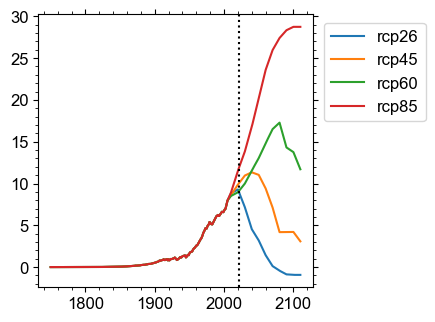

In [30]:
for scenario in scenarios:
    pl.plot(np.arange(1750, 2111), data_out[scenario][0:361,1], label=scenario)    
    print (scenario, data_out[scenario][250,1])
    print (scenario, data_out[scenario][300,1])
    print (scenario, data_out[scenario][350,1])
           
           
pl.axvline(2021, ls=':', color='k')
pl.legend(bbox_to_anchor=(1.01, 1), loc='upper left')




In [31]:
#'rcp26'
print(data_out['rcp26'].shape)
#data_out['rcp26'][:,1]
print (data_out['rcp26'])

for i in np.arange(0,40):
    if data_out['rcp26'][:,i].any == np.nan:
        print ('nan detected', i)

(361, 40)
[[ 1.750000e+03  3.000000e-03  0.000000e+00 ...  0.000000e+00
   1.572670e+02  3.100211e+03]
 [ 1.751000e+03  3.000000e-03  0.000000e+00 ...  0.000000e+00
   1.572670e+02  3.100211e+03]
 [ 1.752000e+03  3.000000e-03  0.000000e+00 ...  0.000000e+00
   1.572670e+02  3.100211e+03]
 ...
 [ 2.108000e+03 -9.308000e-01  3.476840e-01 ...  0.000000e+00
   1.559250e+02  3.511082e+03]
 [ 2.109000e+03 -9.308000e-01  3.272320e-01 ...  0.000000e+00
   1.559250e+02  3.511082e+03]
 [ 2.110000e+03 -9.308000e-01  3.067800e-01 ...  0.000000e+00
   1.559250e+02  3.511082e+03]]


In [32]:
#'rcp45'
#data_out['rcp45'][:,1]
print(data_out['rcp45'].shape)
for i in np.arange(0,40):
    if data_out['rcp45'][:,i].any == np.nan:
        print ('nan detected', i)

(361, 40)


In [33]:
#'rcp60'
#data_out['rcp45'][:,1]
print(data_out['rcp60'].shape)
for i in np.arange(0,40):
    if data_out['rcp60'][:,i].any == np.nan:
        print ('nan detected', i)
        
print(data_out['rcp85'].shape)
for i in np.arange(0,40):
    if data_out['rcp85'][:,i].any == np.nan:
        print ('nan detected', i)

(361, 40)
(361, 40)


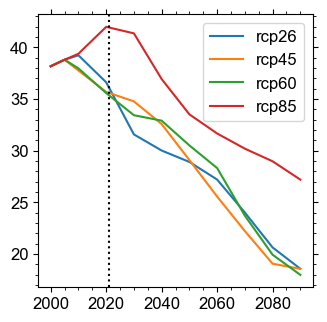

In [34]:
pl.plot(np.arange(2000, 2091), data_out['rcp26'][250:341,8], label='rcp26')
pl.plot(np.arange(2000, 2091), data_out['rcp45'][250:341,8], label='rcp45')
#pl.plot(np.arange(2000, 2091), ssp126[250:341, 39])
pl.plot(np.arange(2000, 2091), data_out['rcp60'][250:341,8], label='rcp60')
pl.plot(np.arange(2000, 2091), data_out['rcp85'][250:341,8], label='rcp85')
pl.axvline(2021, ls=':', color='k')
pl.legend()

# Kyoto gases 

In [35]:
for scenario in scenarios:
    print('scenario ',scenario)
    print(data_out[scenario].shape)

scenario  rcp26
(361, 40)
scenario  rcp45
(361, 40)
scenario  rcp60
(361, 40)
scenario  rcp85
(361, 40)


In [36]:
for scenario in scenarios:
    print('scenario ',scenario)

    #  Year FossilCO2  OtherCO2       CH4       N2O       NOx     NMVOC        CO       SOx       SOx       SOx       CF4      C2F6    HFC125   HFC134a   HFC143a  HFC227ea  HFC245fa       SF6
    #          GtC/yr    GtC/yr  MtCH4/yrMtN2O-N/yr    MtN/yr     Mt/yr   MtCO/yr    MtS/yr    MtS/yr    MtS/yr     kt/yr     kt/yr     kt/yr     kt/yr     kt/yr     kt/yr     kt/yr     kt/yr
    #co2,co2,ch4,n2o,nox,nmvoc,co,sox,sox,sox,cf4,c2f6,hfc125,hfc134a,hfc143a,hfc227ea,hfc245fa,sf6
    d =dict()
    scen_co2e =dict()
    species_col = species.copy()
    species_col.insert(0,'year')
    # Kyoto gases are CO2,CH4, N2O,CF4,C2F6,HFC125,HFC134a,HFC143a,HFC227ea,HFC245fa, SF6
    #Kyoto gases are held in columns 1,2,3,4,13,14,19,20,21,22,23,24
    # Check species and columns
    #print('CO2,CH4, N2O,CF4,C2F6,C6F14,HFC23,HFC32,HFC4310mee,HFC125,HFC134a,HFC143a,HFC227ea,HFC245fa, SF6')
    #print(species_col[1:5],species_col[12],species_col[13],
      #species_col[14],species_col[15],species_col[16],
      #species_col[17],species_col[18],species_col[19],
      #species_col[20],species_col[21],species_col[22],species_col[23])
 
 
 
    conv_ar5 ={species_col[1]: 1,species_col[2]:1,species_col[3]:28,species_col[4]:265,
           species_col[12]:6630,species_col[13]:11100,species_col[14]:7910,
           species_col[15]:12400, species_col[16]:677,species_col[17]:1650,
           species_col[18]:3170,species_col[19]:1300, species_col[20]:4800,
           species_col[21]:3350,species_col[22]:858,species_col[23]:23500}
 
    conv_ar6 ={species_col[1]: 1,species_col[2]:1,species_col[3]:27.9,species_col[4]:273,
       species_col[12]:7380,species_col[13]:12400,species_col[14]:8620,species_col[15]:14600,
       species_col[16]: 771,species_col[17]:1600,species_col[18]:3740,species_col[19]:1530,
       species_col[20]:5810,species_col[21]:3600,species_col[22]:787,species_col[23]:24300}
    conv1 = 44./12.
    #print (data_out[scenario].shape,)
    p_df = pd.DataFrame(data_out[scenario],columns=species_col)
    dat_co2e= np.ones((361, 40)) * np.nan
    dat_co2e[:,1] = p_df[species_col[1]].values[:361]*1e3*3.67
    dat_co2e[:,2] = p_df[species_col[2]].values[:361]*1e3*3.67
    dat_co2e [:,3] = p_df[species_col[3]].values[:361]*conv_ar6[species_col[3]]
    dat_co2e [:,4] = p_df[species_col[4]].values[:361]*conv_ar6[species_col[4]]*(44./28.) 
    dat_co2e [:,12] = p_df[species_col[12]].values[:361]*conv_ar6[species_col[12]]*1e-3
    dat_co2e [:,13] = p_df[species_col[13]].values[:361]*conv_ar6[species_col[13]]*1e-3
    dat_co2e [:,14] = p_df[species_col[14]].values[:361]*conv_ar6[species_col[14]]*1e-3
    dat_co2e [:,15] = p_df[species_col[15]].values[:361]*conv_ar6[species_col[15]]*1e-3
    dat_co2e [:,16] = p_df[species_col[16]].values[:361]*conv_ar6[species_col[16]]*1e-3
    dat_co2e [:,17] = p_df[species_col[17]].values[:361]*conv_ar6[species_col[17]]*1e-3
    dat_co2e [:,18] = p_df[species_col[18]].values[:361]*conv_ar6[species_col[18]]*1e-3
    dat_co2e [:,19] = p_df[species_col[19]].values[:361]*conv_ar6[species_col[19]]*1e-3
    dat_co2e [:,20] = p_df[species_col[20]].values[:361]*conv_ar6[species_col[20]]*1e-3
    dat_co2e [:,21] = p_df[species_col[21]].values[:361]*conv_ar6[species_col[21]]*1e-3
    dat_co2e [:,22] = p_df[species_col[22]].values[:361]*conv_ar6[species_col[22]]*1e-3
    dat_co2e [:,23] = p_df[species_col[23]].values[:361]*conv_ar6[species_col[23]]*1e-3
 
    
    totghg = np.nansum(dat_co2e[:,1:],axis=1)# total co2e
    edx = np.where(data_out[scenario][:,0]==2020)[0][0]
    d  = totghg[edx]*1e-3 # Convert values back into GtCO2e here
    scen_co2e[scenario] = totghg

    print(scen_co2e[scenario][280], scen_co2e[scenario][300],scen_co2e[scenario][350] )

scenario  rcp26
40217.621640499994 21709.2091804 6144.872059899999
scenario  rcp45
54995.5070884 55319.56810169999 27889.953974599994
scenario  rcp60
48413.192199299985 61510.18791889999 64166.06078209999
scenario  rcp85
73178.1147845 102699.69143259998 139918.61024539996


# RCP26

In [37]:
results_out = {}

In [38]:
data_out['rcp26']

array([[ 1.750000e+03,  3.000000e-03,  0.000000e+00, ...,  0.000000e+00,
         1.572670e+02,  3.100211e+03],
       [ 1.751000e+03,  3.000000e-03,  0.000000e+00, ...,  0.000000e+00,
         1.572670e+02,  3.100211e+03],
       [ 1.752000e+03,  3.000000e-03,  0.000000e+00, ...,  0.000000e+00,
         1.572670e+02,  3.100211e+03],
       ...,
       [ 2.108000e+03, -9.308000e-01,  3.476840e-01, ...,  0.000000e+00,
         1.559250e+02,  3.511082e+03],
       [ 2.109000e+03, -9.308000e-01,  3.272320e-01, ...,  0.000000e+00,
         1.559250e+02,  3.511082e+03],
       [ 2.110000e+03, -9.308000e-01,  3.067800e-01, ...,  0.000000e+00,
         1.559250e+02,  3.511082e+03]])

In [39]:
updated_config = []
for i, cfg in enumerate(config_list):
    updated_config.append({})
    for key, value in cfg.items():
        if isinstance(value, list):
            updated_config[i][key] = np.asarray(value)
        else:
            updated_config[i][key] = value
    updated_config[i]['emissions'] = data_out['rcp26']
    updated_config[i]['diagnostics'] = 'AR6'
    updated_config[i]["efficacy"] = np.ones(45)
    updated_config[i]["gir_carbon_cycle"] = True
    updated_config[i]["temperature_function"] = "Geoffroy"
    updated_config[i]["aerosol_forcing"] = "aerocom+ghan2"
    updated_config[i]["fixPre1850RCP"] = False
    updated_config[i]["scale"][43] = 0.6

In [40]:
print (updated_config[i]['emissions'].shape)
print (updated_config[i]['emissions'])

(361, 40)
[[ 1.750000e+03  3.000000e-03  0.000000e+00 ...  0.000000e+00
   1.572670e+02  3.100211e+03]
 [ 1.751000e+03  3.000000e-03  0.000000e+00 ...  0.000000e+00
   1.572670e+02  3.100211e+03]
 [ 1.752000e+03  3.000000e-03  0.000000e+00 ...  0.000000e+00
   1.572670e+02  3.100211e+03]
 ...
 [ 2.108000e+03 -9.308000e-01  3.476840e-01 ...  0.000000e+00
   1.559250e+02  3.511082e+03]
 [ 2.109000e+03 -9.308000e-01  3.272320e-01 ...  0.000000e+00
   1.559250e+02  3.511082e+03]
 [ 2.110000e+03 -9.308000e-01  3.067800e-01 ...  0.000000e+00
   1.559250e+02  3.511082e+03]]


In [41]:
def run_fair(args):
    thisC, thisF, thisT, _, thisOHU, _, thisAF = fair.forward.fair_scm(**args)
    return (thisC[:,0], thisT, np.sum(thisF[:,:43], axis=1), np.sum(thisF[:,35:41], axis=1), np.sum(thisF, axis=1))

if __name__ == '__main__':
    with Pool(28) as pool:
        result = list(tqdm(pool.imap(run_fair, updated_config), total=len(updated_config)))

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2237/2237 [01:14<00:00, 30.21it/s]


In [42]:
len(result[0])

5

In [43]:
result_t = np.array(result).transpose(1,2,0)

In [44]:
results_out['rcp26'] = {}
c, t, f_ant, f_aer, f_tot = result_t
temp_rebase = t - t[100:151,:].mean(axis=0)
results_out['rcp26']['co2_conc'] = c
results_out['rcp26']['temp'] = temp_rebase
results_out['rcp26']['F_ant'] = f_ant
results_out['rcp26']['F_aer'] = f_aer
results_out['rcp26']['F_tot'] = f_tot

(361, 2237)
[[0.03603696 0.01836843 0.0598861  ... 0.03517737 0.01348976 0.02393861]
 [0.06400251 0.02923235 0.0903617  ... 0.05978719 0.02199074 0.04096745]
 [0.08411397 0.03245165 0.10130143 ... 0.07402937 0.02447258 0.05036959]
 ...
 [1.446037   1.29173096 1.03371453 ... 1.50429515 1.48690921 1.62724995]
 [1.44077758 1.28971544 1.03138646 ... 1.50056553 1.4824872  1.62264333]
 [1.43726793 1.28927608 1.03146944 ... 1.49882611 1.4799945  1.61975372]]


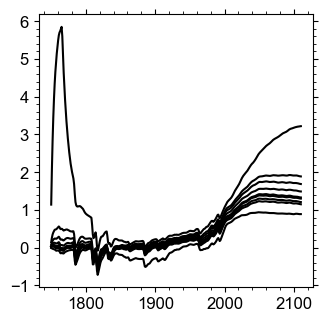

In [45]:
#temp_df = pd.read_csv('../data_input/observations/temp.csv', index_col=0)
#temp_df
print(t.shape)
print(t[:,:])
for perc in [0,5,10,20,25,50,75,90,100]:
    pl.plot(np.arange(1750,2111),np.percentile(t,perc, axis=1), color='k')


In [46]:
print(c.shape)
print(c[:,:])

(361, 2237)
[[275.61841964 276.95088567 273.90748947 ... 276.32775573 276.11438601
  279.29029197]
 [275.61884411 276.95133431 273.90791651 ... 276.32815642 276.11485258
  279.29068456]
 [275.61969641 276.95222249 273.90877325 ... 276.32897492 276.11576895
  279.29149088]
 ...
 [421.52791115 417.22047222 421.66341138 ... 421.99305531 414.3314201
  420.89096007]
 [421.06498835 416.77317672 421.19378765 ... 421.52576592 413.87470655
  420.43655943]
 [420.60105992 416.32513882 420.72311204 ... 421.05747334 413.41747993
  419.98124373]]


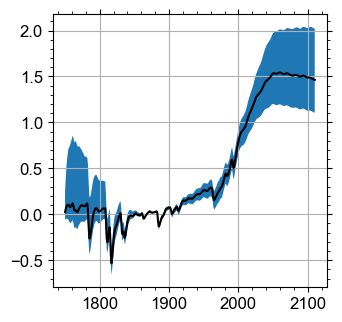

In [47]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['rcp26']['temp'], 5, axis=1), np.percentile(results_out['rcp26']['temp'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['rcp26']['temp'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
#pl.ylim(0.0, 1.7)
#pl.xlim(1950, 2030)
pl.grid()

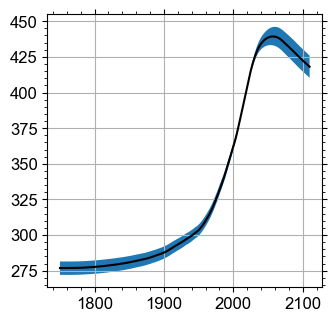

In [48]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['rcp26']['co2_conc'], 5, axis=1), np.percentile(results_out['rcp26']['co2_conc'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['rcp26']['co2_conc'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
#pl.ylim(0.0, 1.7)
#pl.xlim(1950, 2030)
pl.grid()

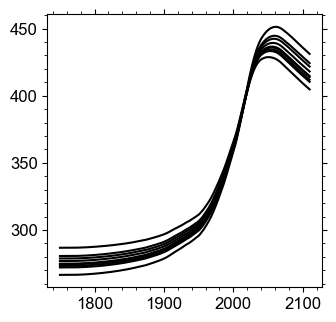

In [49]:
for perc in [0,5,10,20,25,50,75,90,100]:
    pl.plot(np.arange(1750,2111),np.percentile(c,perc, axis=1), color='k')

In [50]:
# pl.fill_between(np.arange(1750,2111), np.percentile(C_CO2, 5, axis=1), np.percentile(C_CO2, 95, axis=1))
# pl.plot(np.arange(1750,2111), np.percentile(C_CO2, 50, axis=1), color='k')
# pl.grid()

In [51]:
# np.percentile(T2, 50, axis=1)[260:270].mean()

In [52]:
# pl.fill_between(np.arange(1750,2111), np.percentile(F_ant, 5, axis=1), np.percentile(F_ant, 95, axis=1))
# pl.plot(np.arange(1750,2111), np.percentile(F_ant, 50, axis=1), color='k')
# pl.grid()

In [53]:
# pl.fill_between(np.arange(1750,2111), np.percentile(F_aer, 5, axis=1), np.percentile(F_aer, 95, axis=1))
# pl.plot(np.arange(1750,2111), np.percentile(F_aer, 50, axis=1), color='k')
# pl.grid()

In [54]:
np.median(results_out['rcp26']['temp'], axis=1)[245:265].mean()

0.8610660572169522

In [55]:
# aerosol forcing is a little less negative than in WG3 because we use CEDS-updated not SSP historical
print(
    np.percentile(results_out['rcp26']['F_aer'], 5, axis=1)[255:265].mean(),
    np.percentile(results_out['rcp26']['F_aer'], 50, axis=1)[255:265].mean(),
    np.percentile(results_out['rcp26']['F_aer'], 95, axis=1)[255:265].mean()
)

-1.698515926332859 -1.1438010072132534 -0.6047461483404216


# rcp45

In [56]:
for i, cfg in enumerate(updated_config):
    updated_config[i]['emissions'] = data_out['rcp45']

In [57]:
if __name__ == '__main__':
    with Pool(28) as pool:
        result = list(tqdm(pool.imap(run_fair, updated_config), total=len(updated_config)))

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2237/2237 [01:08<00:00, 32.47it/s]


In [58]:
results_out['rcp45'] = {}
result_t = np.array(result).transpose(1,2,0)
c, t, f_ant, f_aer, f_tot = result_t
temp_rebase = t - t[100:151,:].mean(axis=0)
results_out['rcp45']['co2_conc'] = c
results_out['rcp45']['temp'] = temp_rebase
results_out['rcp45']['F_ant'] = f_ant
results_out['rcp45']['F_aer'] = f_aer
results_out['rcp45']['F_tot'] = f_tot

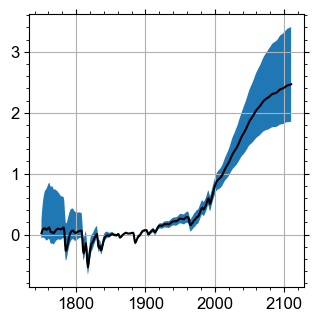

In [59]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['rcp45']['temp'], 5, axis=1), np.percentile(results_out['rcp45']['temp'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['rcp45']['temp'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
#pl.ylim(0.0, 1.7)
#pl.xlim(1950, 2030)
pl.grid()

# rcp60

In [60]:
for i, cfg in enumerate(updated_config):
    updated_config[i]['emissions'] = data_out['rcp60']

In [61]:
if __name__ == '__main__':
    with Pool(28) as pool:
        result = list(tqdm(pool.imap(run_fair, updated_config), total=len(updated_config)))

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2237/2237 [01:13<00:00, 30.42it/s]


In [62]:
results_out['rcp60'] = {}
result_t = np.array(result).transpose(1,2,0)
c, t, f_ant, f_aer, f_tot = result_t
temp_rebase = t - t[100:151,:].mean(axis=0)
results_out['rcp60']['co2_conc'] = c
results_out['rcp60']['temp'] = temp_rebase
results_out['rcp60']['F_ant'] = f_ant
results_out['rcp60']['F_aer'] = f_aer
results_out['rcp60']['F_tot'] = f_tot

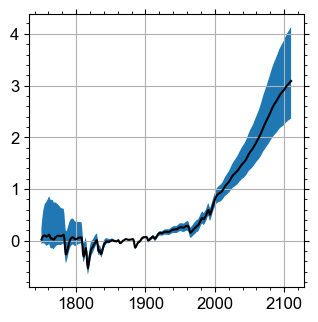

In [63]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['rcp60']['temp'], 5, axis=1), np.percentile(results_out['rcp60']['temp'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['rcp60']['temp'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
#pl.ylim(0.0, 1.7)
#pl.xlim(1950, 2030)
pl.grid()

# rcp85

In [64]:
for i, cfg in enumerate(updated_config):
    updated_config[i]['emissions'] = data_out['rcp85']

if __name__ == '__main__':
    with Pool(28) as pool:
        result = list(tqdm(pool.imap(run_fair, updated_config), total=len(updated_config)))

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 2237/2237 [01:14<00:00, 29.89it/s]


In [65]:
results_out['rcp85'] = {}
result_t = np.array(result).transpose(1,2,0)
c, t, f_ant, f_aer, f_tot = result_t
temp_rebase = t - t[100:151,:].mean(axis=0)
results_out['rcp85']['co2_conc'] = c
results_out['rcp85']['temp'] = temp_rebase
results_out['rcp85']['F_ant'] = f_ant
results_out['rcp85']['F_aer'] = f_aer
results_out['rcp85']['F_tot'] = f_tot

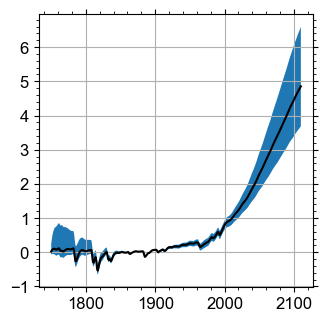

In [66]:
pl.fill_between(np.arange(1750,2111), np.percentile(results_out['rcp85']['temp'], 5, axis=1), np.percentile(results_out['rcp85']['temp'], 95, axis=1))
pl.plot(np.arange(1750,2111), np.percentile(results_out['rcp85']['temp'], 50, axis=1), color='k')
#pl.plot(temp_df.index, temp_df.temp, color='r')
pl.grid()

# All on the same plot!

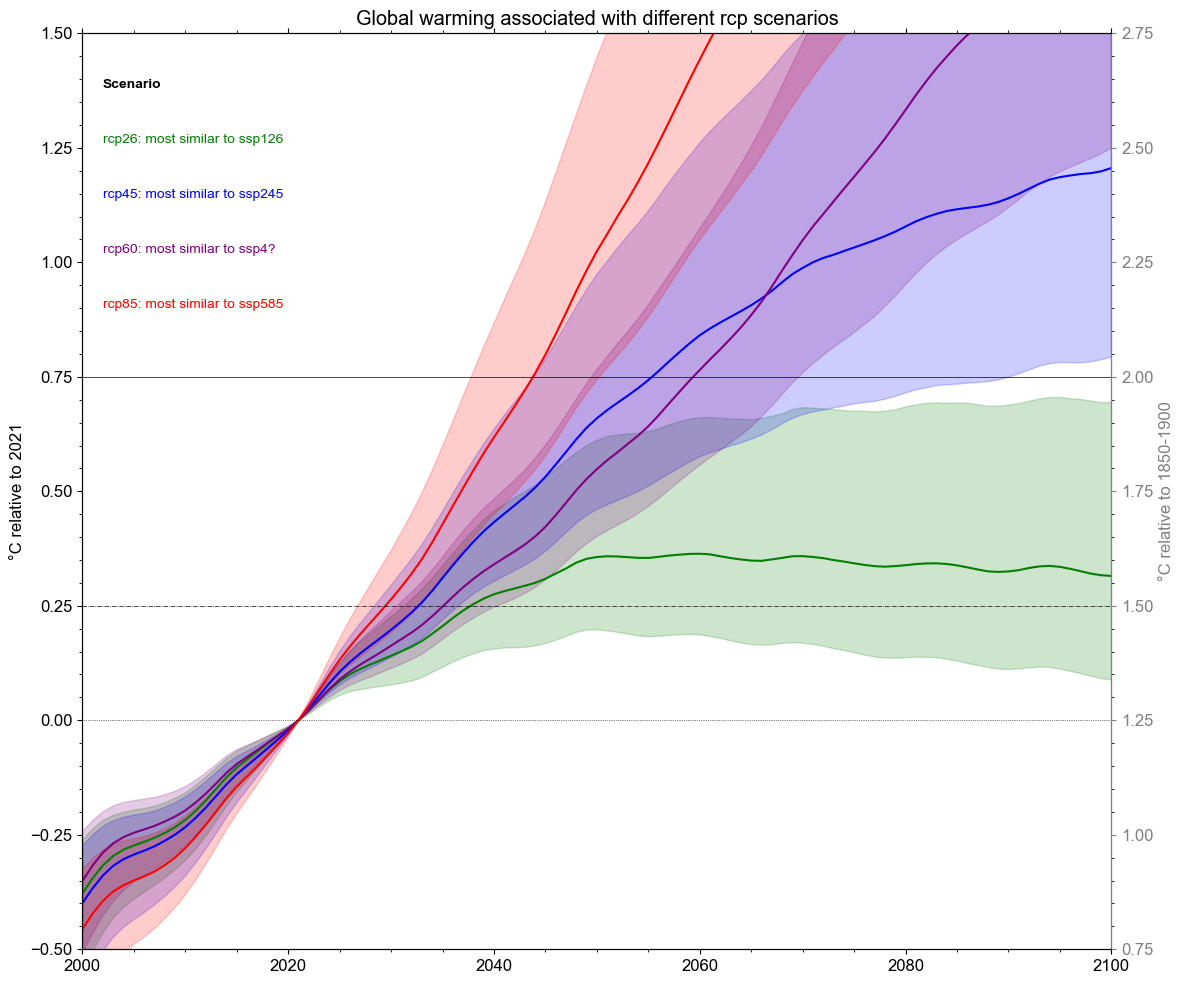

In [67]:
#scenarios = ['zero', 'constant_forcing', 'constant_emissions', 'infrastructure', 'scenario']
scenarios = ['rcp26','rcp45','rcp60','rcp85']
colors = {
    'rcp26' : 'green',
    'rcp45' : 'blue',
    'rcp60' : 'purple',
    'rcp85' : 'red'
    }

labels = {
    'rcp26' : 'rcp26: most similar to ssp126',
    'rcp45' : 'rcp45: most similar to ssp245',
    'rcp60' : 'rcp60: most similar to ssp4?',
    'rcp85' : 'rcp85: most similar to ssp585'
}

fig, ax = pl.subplots(figsize=(12, 10))

ax.text(0.02, 0.94, 'Scenario', fontweight='bold', fontsize=10, transform=ax.transAxes)
for i, scenario in enumerate(['rcp26', 'rcp45', 'rcp60','rcp85']):
    ax.fill_between(np.arange(2000,2101), np.percentile(results_out[scenario]['temp'][250:351,:] - results_out[scenario]['temp'][271,:], 5, axis=1), np.percentile(results_out[scenario]['temp'][250:351,:] - results_out[scenario]['temp'][271,:], 95, axis=1), color=colors[scenario], alpha=0.2)
    ax.plot(np.arange(2000, 2101), np.median(results_out[scenario]['temp'][250:351,:] - results_out[scenario]['temp'][271,:], axis=1), color=colors[scenario], label=labels[scenario])
    ax.text(0.02, 0.88-0.06*i, labels[scenario], color=colors[scenario], transform=ax.transAxes, fontsize=10)
#ax.legend(fontsize=10);
ax.set_ylabel('°C relative to 2021');
ax.set_title('Global warming associated with different rcp scenarios');
ax.set_xlim(2000, 2100)
ax.set_ylim(-0.5, 1.5)

from matplotlib import ticker

ax1 = ax.twinx()
positions = np.arange(0.75, 2.76, 0.25)
#ax1.plot(temp_df.index[150:], temp_df.temp[150:], color='k')
ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))
#ax1[3].xaxis.set_major_formatter(ticker.FixedFormatter(labels))
ax1.set_ylim(0.75,2.75)
ax1.spines['right'].set_color('gray')
ax1.tick_params(axis='y', colors='gray')
ax1.set_ylabel('°C relative to 1850-1900', color='gray')
#ax1.set_yticklabels(np.arange(0.75, 2.26, 0.25))
#pl.grid()

ax.axhline(0, ls=':', color='k', lw=0.5)
ax1.axhline(1.5, ls='-.', color='k', lw=0.5)
ax1.axhline(2.0, ls='-', color='k', lw=0.5)
fig.tight_layout()
pl.savefig('../plots/rcmip_rcp_scenarios_temp.png', dpi=500, transparent=False)

In [68]:
with open('../processed/commit_results_rcmip-rcp-scenarios.pkl', 'wb') as f:
    pickle.dump(results_out, f)

In [69]:
#temp_df.temp[150:].values

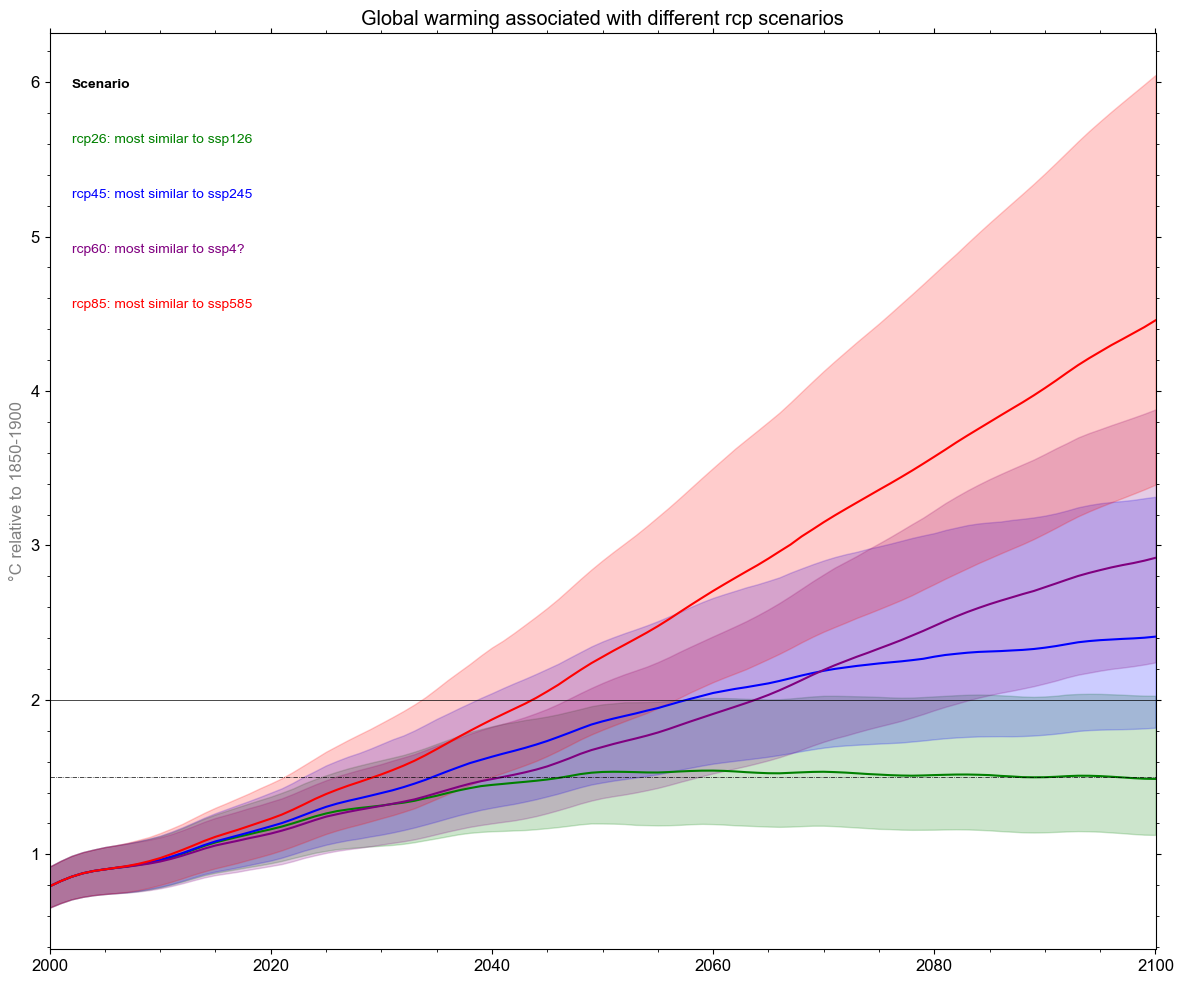

In [70]:
#scenarios = ['zero', 'constant_forcing', 'constant_emissions', 'infrastructure', 'scenario']
scenarios = ['rcp26','rcp45','rcp60','rcp85']
colors = {
    'rcp26' : 'green',
    'rcp45' : 'blue',
    'rcp60' : 'purple',
    'rcp85' : 'red'
    }

labels = {
    'rcp26' : 'rcp26: most similar to ssp126',
    'rcp45' : 'rcp45: most similar to ssp245',
    'rcp60' : 'rcp60: most similar to ssp4?',
    'rcp85' : 'rcp85: most similar to ssp585'
}

fig, ax = pl.subplots(figsize=(12, 10))

ax.text(0.02, 0.94, 'Scenario', fontweight='bold', fontsize=10, transform=ax.transAxes)
for i, scenario in enumerate(['rcp26', 'rcp45', 'rcp60','rcp85']):
    ax.fill_between(np.arange(2000,2101), np.percentile(results_out[scenario]['temp'][250:351,:] , 5, axis=1), np.percentile(results_out[scenario]['temp'][250:351,:], 95, axis=1), color=colors[scenario], alpha=0.2)
    ax.plot(np.arange(2000, 2101), np.median(results_out[scenario]['temp'][250:351,:] , axis=1), color=colors[scenario], label=labels[scenario])
    ax.text(0.02, 0.88-0.06*i, labels[scenario], color=colors[scenario], transform=ax.transAxes, fontsize=10)
#ax.legend(fontsize=10);
#ax.set_ylabel('°C relative to 2021');
ax.set_title('Global warming associated with different rcp scenarios');
ax.set_xlim(2000, 2100)
#ax.set_ylim(-0.5, 1.5)

from matplotlib import ticker

#ax1 = ax.twinx()
positions = np.arange(0.75, 2.76, 0.25)
#ax1.plot(temp_df.index[150:], temp_df.temp[150:], color='k')
#ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))
#ax1[3].xaxis.set_major_formatter(ticker.FixedFormatter(labels))
#ax1.set_ylim(0.75,2.75)
#ax1.spines['right'].set_color('gray')
#ax1.tick_params(axis='y', colors='gray')
ax.set_ylabel('°C relative to 1850-1900', color='gray')
#ax1.set_yticklabels(np.arange(0.75, 2.26, 0.25))
#pl.grid()

#ax.axhline(0, ls=':', color='k', lw=0.5)
ax.axhline(1.5, ls='-.', color='k', lw=0.5)
ax.axhline(2.0, ls='-', color='k', lw=0.5)
fig.tight_layout()
pl.savefig('../plots/rcmip_rcp_scenarios_temp_relPI.png', dpi=500, transparent=False)

# All on the same plot CO2 conc!

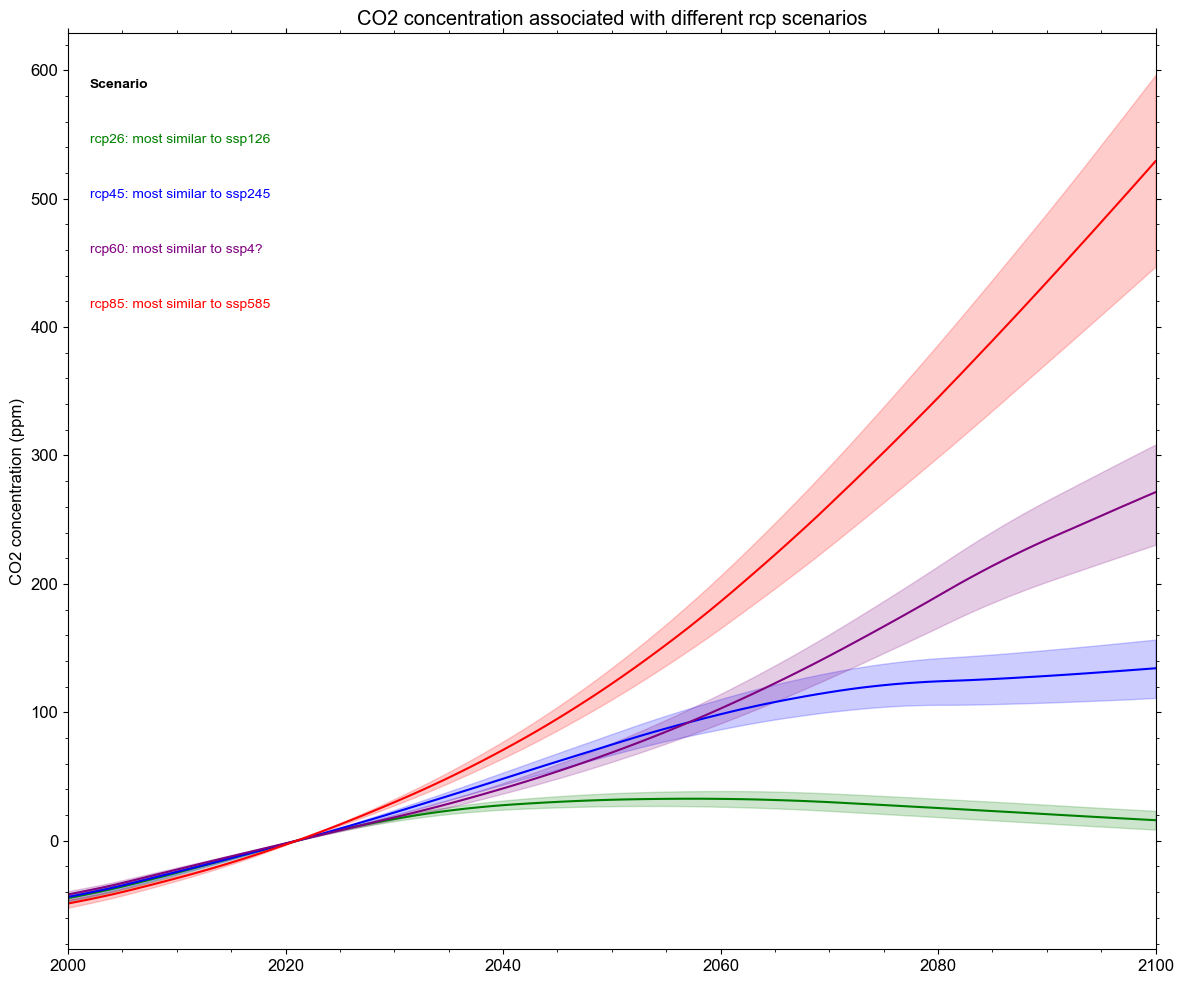

In [71]:
fig, ax = pl.subplots(figsize=(12, 10))

ax.text(0.02, 0.94, 'Scenario', fontweight='bold', fontsize=10, transform=ax.transAxes)
for i, scenario in enumerate(['rcp26', 'rcp45', 'rcp60', 'rcp85']):
    ax.fill_between(np.arange(2000,2101), np.percentile(results_out[scenario]['co2_conc'][250:351,:] - results_out[scenario]['co2_conc'][271,:], 5, axis=1), np.percentile(results_out[scenario]['co2_conc'][250:351,:] - results_out[scenario]['co2_conc'][271,:], 95, axis=1), color=colors[scenario], alpha=0.2)
    ax.plot(np.arange(2000, 2101), np.median(results_out[scenario]['co2_conc'][250:351,:] - results_out[scenario]['co2_conc'][271,:], axis=1), color=colors[scenario], label=labels[scenario])
    ax.text(0.02, 0.88-0.06*i, labels[scenario], color=colors[scenario], transform=ax.transAxes, fontsize=10)
#ax.legend(fontsize=10);
ax.set_ylabel('CO2 concentration (ppm)');
ax.set_title('CO2 concentration associated with different rcp scenarios');
ax.set_xlim(2000, 2100)
#ax.set_ylim(-0.5, 1.5)

from matplotlib import ticker

#ax1 = ax.twinx()
#positions = np.arange(0.75, 2.76, 0.25)
#ax1.plot(temp_df.index[150:], temp_df.temp[150:], color='k')
ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))
#ax1[3].xaxis.set_major_formatter(ticker.FixedFormatter(labels))
#ax1.set_ylim(0.75,2.75)
ax1.spines['right'].set_color('gray')
ax1.tick_params(axis='y', colors='gray')
#ax1.set_ylabel('CO2 concentrations relative to 1850-1900', color='gray')
#ax1.set_yticklabels(np.arange(0.75, 2.26, 0.25))
#pl.grid()

#ax.axhline(0, ls=':', color='k', lw=0.5)
#ax1.axhline(1.5, ls='-.', color='k', lw=0.5)
#ax1.axhline(2.0, ls='-', color='k', lw=0.5)
fig.tight_layout()
pl.savefig('../plots/rcmip_rcp_scenarios_CO2conc.png', dpi=500, transparent=False)

# All on the same plot ERF!

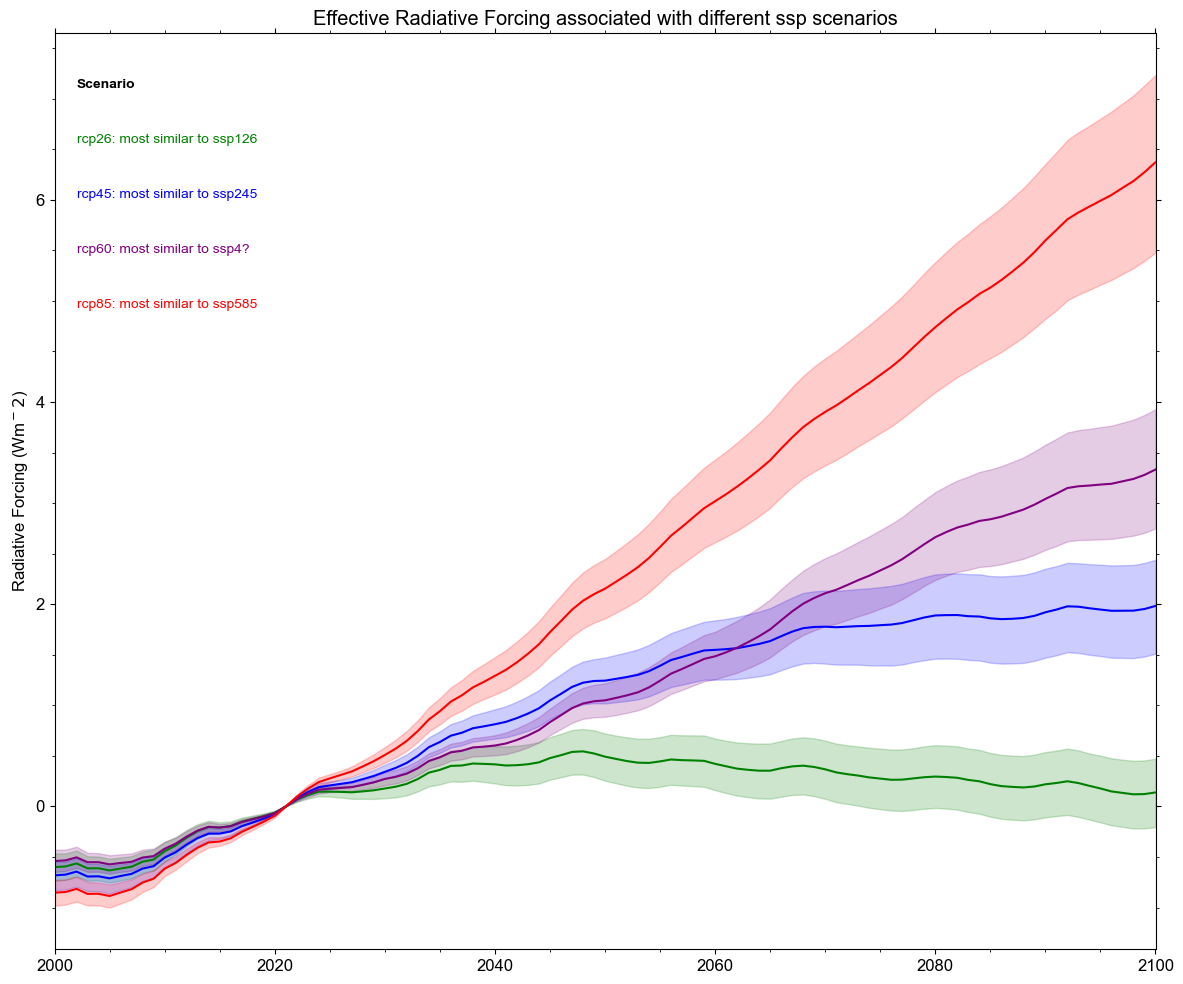

In [72]:
fig, ax = pl.subplots(figsize=(12, 10))

ax.text(0.02, 0.94, 'Scenario', fontweight='bold', fontsize=10, transform=ax.transAxes)
for i, scenario in enumerate(['rcp26', 'rcp45', 'rcp60', 'rcp85']):
    #if scenario in ['ssp119', 'ssp245', 'ssp434']:
    ax.fill_between(np.arange(2000,2101), np.percentile(results_out[scenario]['F_tot'][250:351,:] - results_out[scenario]['F_tot'][271,:], 5, axis=1), np.percentile(results_out[scenario]['F_tot'][250:351,:] - results_out[scenario]['F_tot'][271,:], 95, axis=1), color=colors[scenario], alpha=0.2)
    ax.plot(np.arange(2000, 2101), np.median(results_out[scenario]['F_tot'][250:351,:] - results_out[scenario]['F_tot'][271,:], axis=1), color=colors[scenario], label=labels[scenario])
    ax.text(0.02, 0.88-0.06*i, labels[scenario], color=colors[scenario], transform=ax.transAxes, fontsize=10)
#ax.legend(fontsize=10);
ax.set_ylabel(r'Radiative Forcing (Wm${^-2}$)');
ax.set_title('Effective Radiative Forcing associated with different ssp scenarios');
ax.set_xlim(2000, 2100)
#ax.set_ylim(-0.5, 1.5)

from matplotlib import ticker

#ax1 = ax.twinx()
#positions = np.arange(0.75, 2.76, 0.25)
#ax1.plot(temp_df.index[150:], temp_df.temp[150:], color='k')
ax1.yaxis.set_major_locator(ticker.FixedLocator(positions))
#ax1[3].xaxis.set_major_formatter(ticker.FixedFormatter(labels))
#ax1.set_ylim(0.75,2.75)
ax1.spines['right'].set_color('gray')
ax1.tick_params(axis='y', colors='gray')
#ax1.set_ylabel('CO2 concentrations relative to 1850-1900', color='gray')
#ax1.set_yticklabels(np.arange(0.75, 2.26, 0.25))
#pl.grid()

#ax.axhline(0, ls=':', color='k', lw=0.5)
#ax1.axhline(1.5, ls='-.', color='k', lw=0.5)
#ax1.axhline(2.0, ls='-', color='k', lw=0.5)
fig.tight_layout()
pl.savefig('../plots/rcmip_rcp_scenarios_erf.png', dpi=500, transparent=False)

In [73]:
for i, scenario in enumerate(['rcp26', 'rcp45','rcp60', 'rcp85']):
    print('scenario ',scenario)
    print('median', np.median(results_out[scenario]['temp'][280,:]), np.median(results_out[scenario]['temp'][300,:]), np.median(results_out[scenario]['temp'][350,:]))
    print('50th percentile', np.percentile(results_out[scenario]['temp'][:361,:], 50, axis=1)[280], np.percentile(results_out[scenario]['temp'][:361,:], 50, axis=1)[300], np.percentile(results_out[scenario]['temp'][:361,:], 50, axis=1)[350])
    print('5th percentile', np.percentile(results_out[scenario]['temp'][:361,:], 5, axis=1)[280], np.percentile(results_out[scenario]['temp'][:361,:], 5, axis=1)[300], np.percentile(results_out[scenario]['temp'][:361,:], 5, axis=1)[350])
    print('95th percentile', np.percentile(results_out[scenario]['temp'][:361:], 95, axis=1)[280], np.percentile(results_out[scenario]['temp'][:361:], 95, axis=1)[300],np.percentile(results_out[scenario]['temp'][:361,:], 95, axis=1)[350])


scenario  rcp26
median 1.315822694664993 1.5334295007710503 1.488269621518722
50th percentile 1.315822694664993 1.5334295007710503 1.488269621518722
5th percentile 1.0558183384533373 1.1997404834296572 1.1258389915857172
95th percentile 1.609331529750738 1.9711900084358926 2.026670944333513
scenario  rcp45
median 1.3969399329386807 1.8611044512483725 2.4097291006956185
50th percentile 1.3969399329386807 1.8611044512483725 2.4097291006956185
5th percentile 1.1274559084752924 1.465468930207687 1.820189744521622
95th percentile 1.7140011875986945 2.3782686770568855 3.3152003502586216
scenario  rcp60
median 1.3139372289800024 1.695095604556862 2.9199077862247074
50th percentile 1.3139372289800024 1.695095604556862 2.9199077862247074
5th percentile 1.0633555375802963 1.3643863761389652 2.242785670657058
95th percentile 1.5844083043434287 2.109607264692529 3.8806865637178003
scenario  rcp85
median 1.5177001386112072 2.2786132090122297 4.457673309990137
50th percentile 1.5177001386112072 2.27

# Cumulative CO2 to 2100